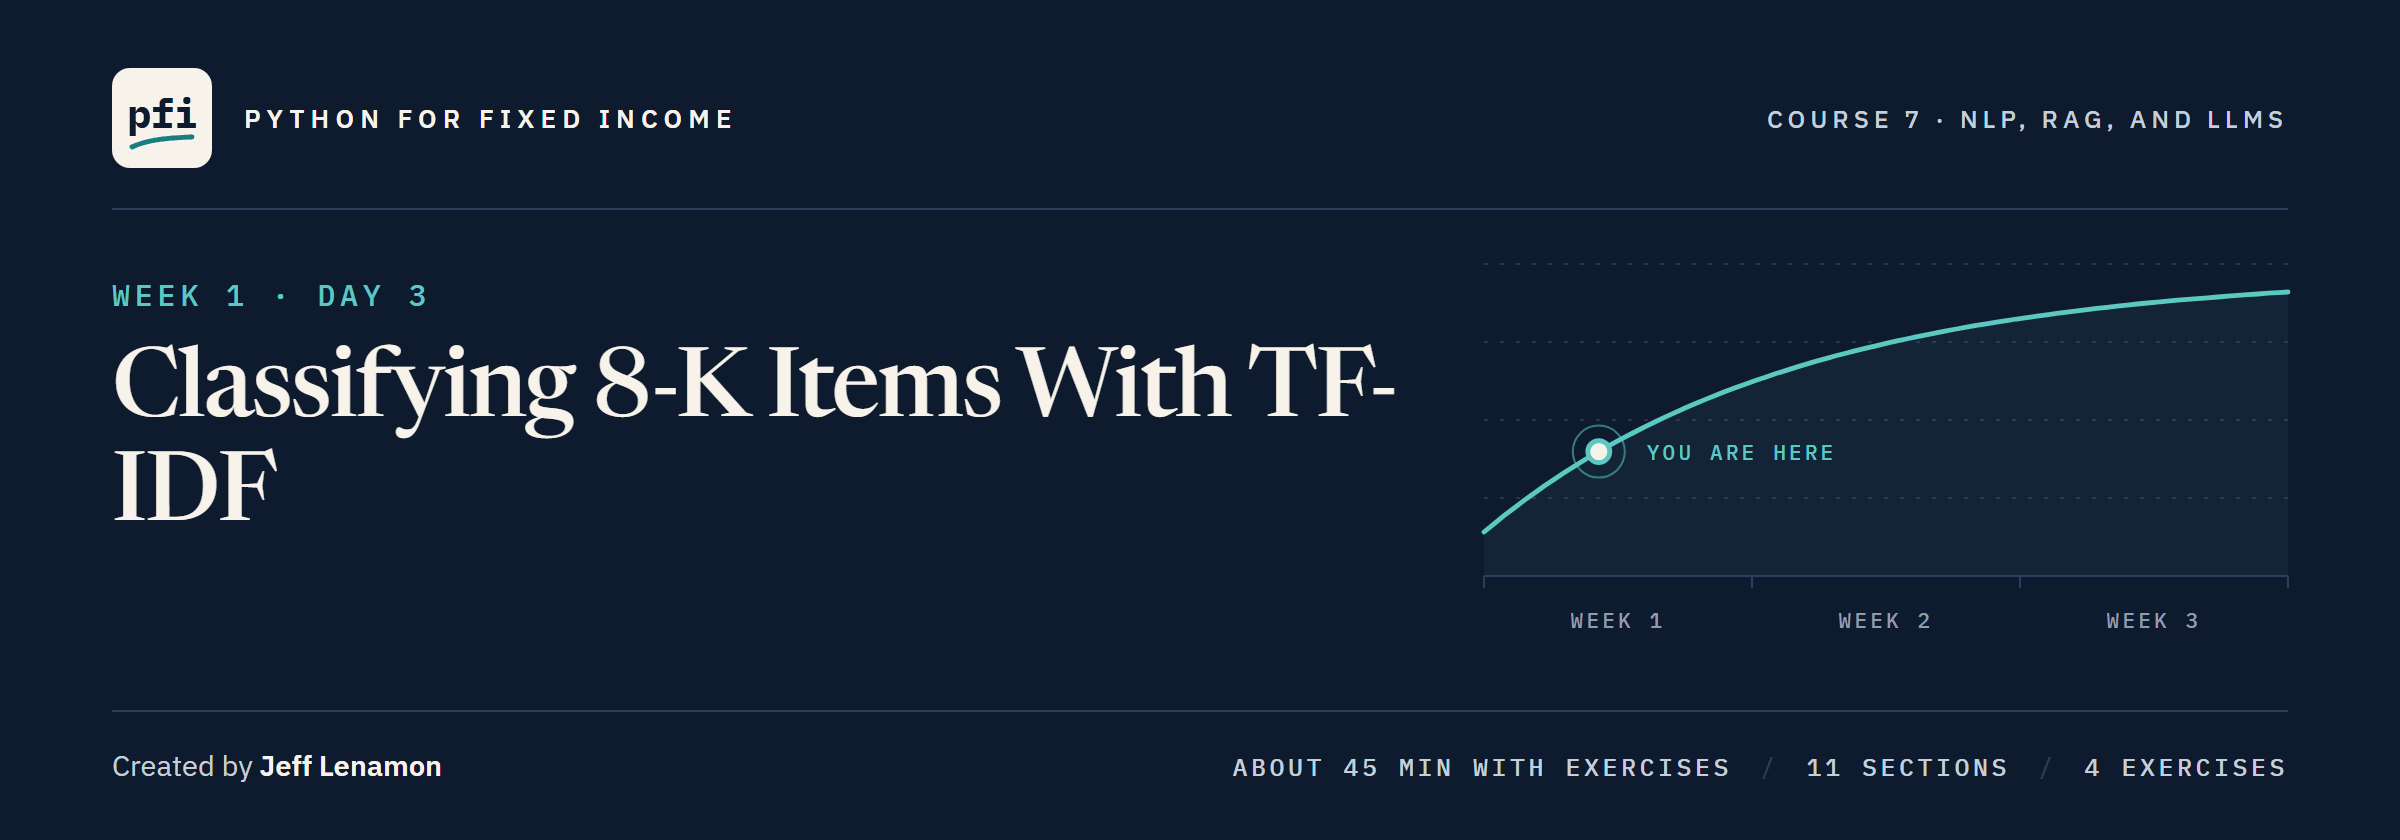

# Classifying 8-K Items With TF-IDF

Week 1, Day 3. Teach a model to assign each 8-K section one of eight items, and score it on later filings with every item counted the same.

**Data:** `course7_8k_items.csv`, 5,126 item sections of Form 8-K current reports filed on EDGAR, 2019 to 2025, each labelled by the item its filer chose: **real**, public records (sec.gov), a sample drawn by the course (DATA.md).

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day3/03_classifying_8k_items_with_tf_idf.ipynb)

# Problem Statement

## Business Context

A company files a Form 8-K current report within days of an event, and each event sits under a numbered item the filer chose.
Item 1.01 is a material agreement, 1.03 a bankruptcy or receivership, 2.04 a triggering event that accelerates an obligation, and five more.
A credit desk wants each section routed to the reader who follows its item.
The file holds 5,126 real sections filed 2019 to 2025, drawn by the course at most 100 per item a year, so how rare an item is here is the course's design.
The item is the label its filer chose; the model's output is the item it assigns, never a judgement of the company.
Every model is fitted on 2019 to 2023 and chosen on 2024, and the 2025 sections stay closed until Day 10.

## Objectives

Read an 8-K file and the design that drew it.
Split dated filings into training, validation and closed test rows by date.
Score eight items with macro F1 and per-item recall against a baseline.
Measure what a label left in the text does to a score.
Fit TF-IDF and a logistic regression as one pipeline.
Read an eight-item confusion matrix.
Turn class weights and the penalty `C`, and choose on validation rows.
Read a model's coefficients as what it leans on, never as reasons.

## Data Dictionary

`course7_8k_items.csv`, one row per item section:

1. `accession`: the SEC's number for the filing
2. `cik`: the SEC's number for the company
3. `company`: the filer, named only in source lines
4. `filed`: the filing date, as text
5. `item`: the item code as text, the label
6. `item_title`: the SEC's title for the item
7. `words`: the section's length as filed
8. `text`: its first 300 words, the heading cut by the course's tool
9. `url`: the filing on sec.gov

Item 5.02 sections name officers and directors, so no 5.02 text is ever printed.

Made in the notebook: `LABELS` (the eight codes), `train` and `valid` (the two open roles), `model` (the first classifier), `fits` (ten settings) and `chosen` (the course's classifier).

## Your Route Through Day 3

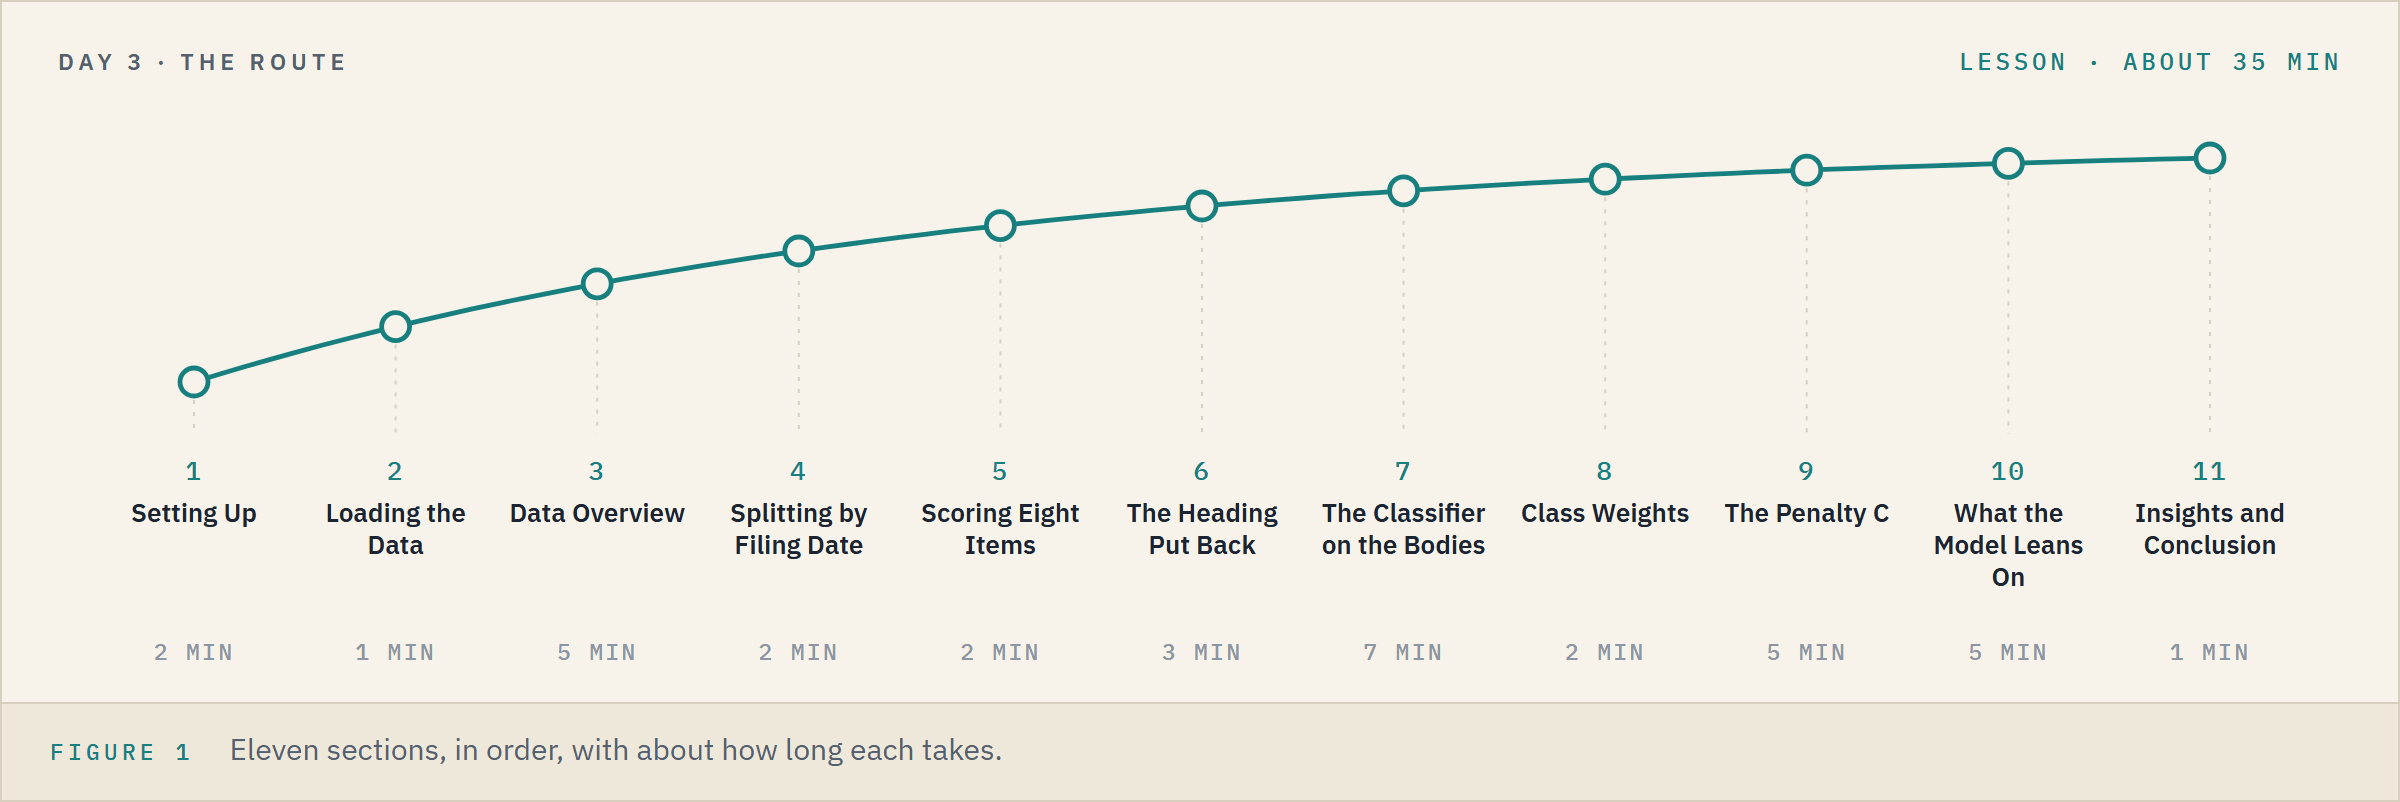

**Time.** About 35 minutes for the lesson, then about 12 for the four exercises.

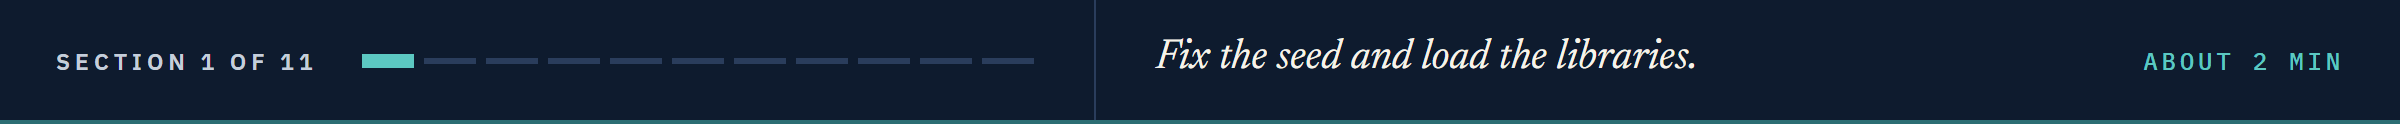

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text: regular expressions and Unicode forms
import re
import unicodedata

# data, charts and a slider; Path from matplotlib draws a curve, so it is named CurvePath here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.path import Path as CurvePath
from matplotlib.patches import PathPatch
from ipywidgets import interact

# scikit-learn: the vectorizer, the classifier, the pipeline, a baseline and the scores
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## Day 1's Pieces in One Cell

Day 1 wrote these lines; they are repeated here as one cell, unchanged, with Day 1's source line in the form of an 8-K section.
Every excerpt prints through `normalize_text`, and `TOKEN_PATTERN` is the vectorizer's token.

In [3]:
# Day 1's map of look-alike characters and normalize_text
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


# Day 1's token
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"


# Day 1's source line, in the same form for one 8-K section
def section_source(row):
    """Print the source line of one 8-K section."""
    print(f"Source: {row['company']}, Form 8-K filed {row['filed']}, accession {row['accession']}, Item {row['item']}, {row['url']}")

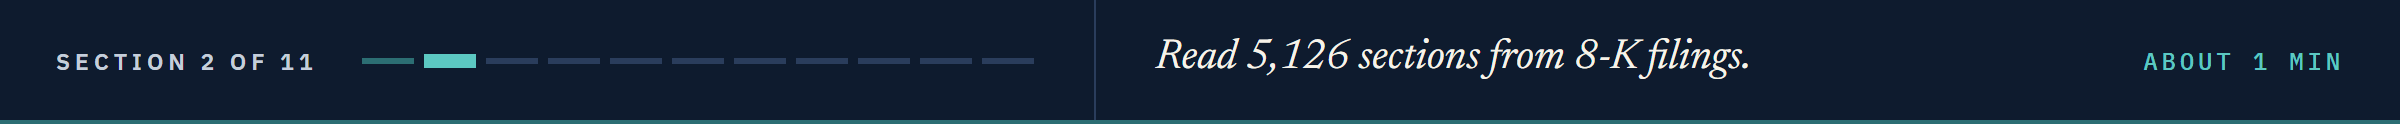

# Loading the Data

## The Sections

In [4]:
# the 5,126 sections; the item code is read as text, so "2.10" would never become 2.1 (Day 1's numbers as text)
eightk = pd.read_csv(DATA + "course7_8k_items.csv", dtype={"item": str})
print(eightk.shape, "|", eightk["accession"].nunique(), "filings |", eightk["cik"].nunique(), "companies")

# how many filings hold one section, two, three
print(eightk["accession"].value_counts().value_counts().sort_index().to_dict())

(5126, 9) | 4965 filings | 2907 companies
{1: 4806, 2: 157, 3: 2}


4,806 filings hold one section, 157 hold two, and 2 hold three: one filing can report several events.

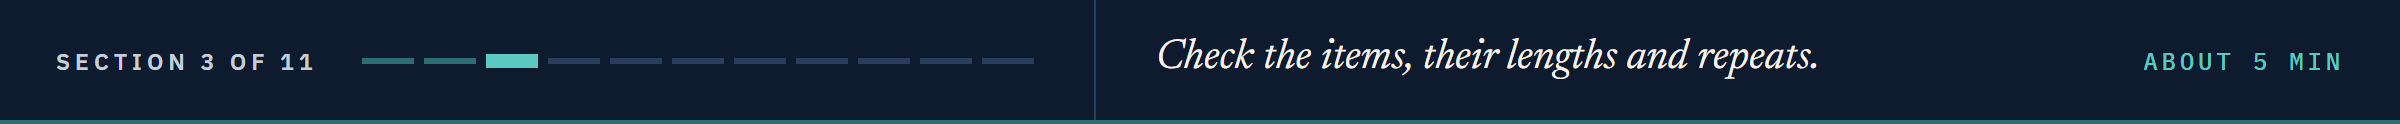

# Data Overview

## Missing Values, Dates and Characters

In [5]:
# missing values in every column, and the first and last filing dates
print(eightk.isna().sum().sum(), "missing |", eightk["filed"].min(), "to", eightk["filed"].max())

# Day 1's normalize_text on every stored body: how many it would change
print((eightk["text"].map(normalize_text) != eightk["text"]).sum(), "of", len(eightk), "bodies change")

# two invisible characters that are not look-alikes: in how many sections, and how many sit between two letters or digits
for code in [0x200B, 0xFEFF]:
    inside = eightk["text"].str.contains(f"[A-Za-z0-9]{chr(code)}[A-Za-z0-9]").sum()
    print(f"U+{code:04X}", unicodedata.name(chr(code)), "|", eightk["text"].str.contains(chr(code)).sum(), "sections |", inside, "inside a word")

0 missing | 2019-01-02 to 2025-12-31
0 of 5126 bodies change
U+200B ZERO WIDTH SPACE | 84 sections | 0 inside a word
U+FEFF ZERO WIDTH NO-BREAK SPACE | 15 sections | 0 inside a word


The course's tool stored every body already normalised, so the pipeline reads `text` as stored.

The two invisible characters never sit inside a word, so the token pattern reads past them and the map needs no entry.

## The Eight Items

In [6]:
# the eight codes as text, sorted, each with the SEC's title from the file
LABELS = sorted(eightk["item"].unique())
titles = eightk.groupby("item")["item_title"].first()
for item in LABELS:
    print(item, titles[item])

# sections by item and filing year (.str[:4] reads the year from a date written as text)
by_year = pd.crosstab(eightk["item"], eightk["filed"].str[:4])
print(by_year.to_string())
print("in all:", by_year.sum(axis=1).to_dict())

1.01 Entry into a Material Definitive Agreement
1.03 Bankruptcy or Receivership
2.02 Results of Operations and Financial Condition
2.03 Creation of a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement of a Registrant
2.04 Triggering Events That Accelerate or Increase a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement
2.06 Material Impairments
3.01 Notice of Delisting or Failure to Satisfy a Continued Listing Rule or Standard; Transfer of Listing
5.02 Departure of Directors or Certain Officers; Election of Directors; Appointment of Certain Officers; Compensatory Arrangements of Certain Officers
filed  2019  2020  2021  2022  2023  2024  2025
item                                           
1.01    100   100   100   100   100   100   100
1.03     96   100    65    35   100   100    84
2.02    100   100   100   100   100   100   100
2.03    100   100   100   100   100   100   100
2.04    100   100    85    98   100   100  

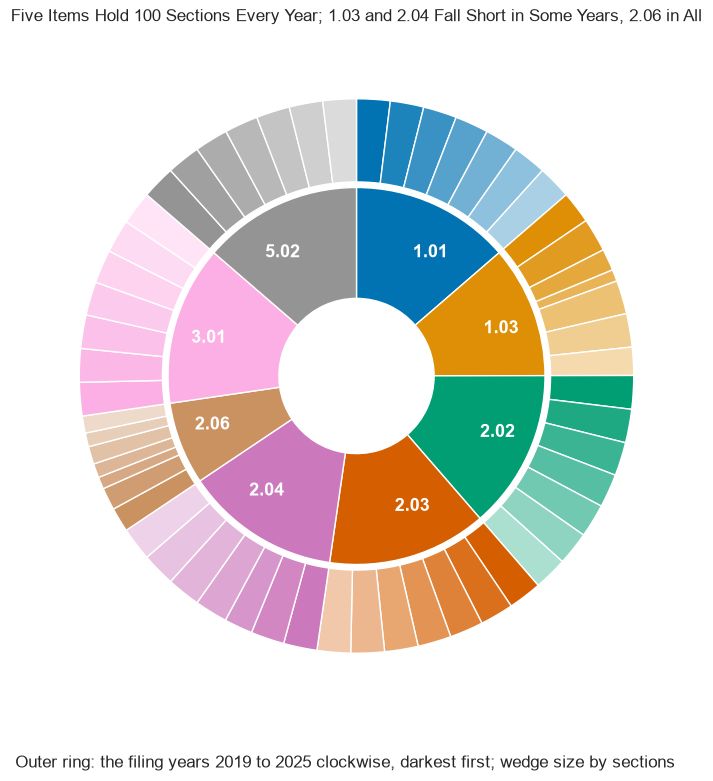

In [7]:
# items as the inner ring, each item's years as the outer ring, 2019 darkest (Course 6's Day 5 sunburst, two ax.pie rings)
colours = sns.color_palette("colorblind", 8)
shades = [tuple(c + (1 - c) * year / 9 for c in colours[i]) for i in range(8) for year in range(7)]
fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(by_year.sum(axis=1), labels=LABELS, colors=colours, radius=0.68, labeldistance=0.72, startangle=90, counterclock=False,
       wedgeprops={"width": 0.4, "edgecolor": "white"}, textprops={"color": "white", "fontsize": 13, "weight": "bold"})
ax.pie(by_year.to_numpy().ravel(), colors=shades, radius=1, startangle=90, counterclock=False, wedgeprops={"width": 0.3, "edgecolor": "white"})
ax.set_title("Five Items Hold 100 Sections Every Year; 1.03 and 2.04 Fall Short in Some Years, 2.06 in All")
plt.figtext(0.5, 0.06, "Outer ring: the filing years 2019 to 2025 clockwise, darkest first; wedge size by sections", ha="center")
plt.show()

Five items hold 700 sections, 100 a year.

1.03 holds 580 (35 in 2022), 2.04 holds 683, and 2.06 holds 363, the smallest.

**The counts show the course's sampling, never how often companies file.**

## How Long a Section Is

median 161.0 | largest 3388 | longer than 300: 1289
{'1.01': 175.0, '1.03': 402.0, '2.02': 118.0, '2.03': 71.0, '2.04': 236.0, '2.06': 196.0, '3.01': 280.0, '5.02': 111.0}


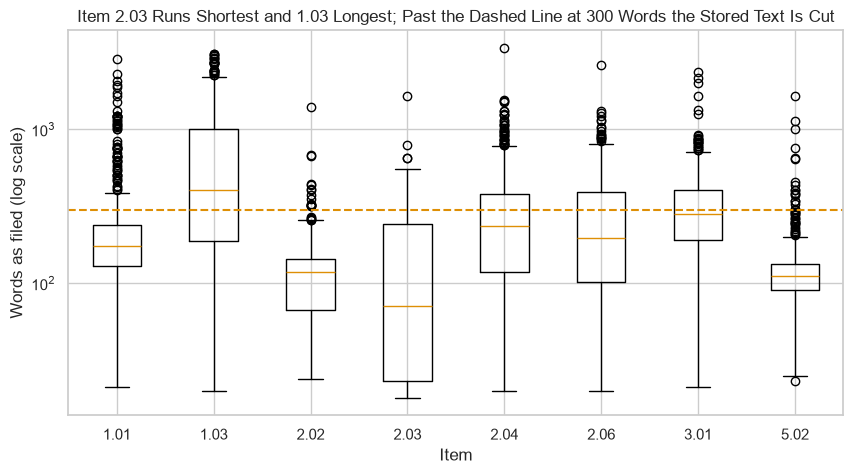

In [8]:
# words as filed: the median, the largest, how many were cut at 300 words, and each item's median
print("median", eightk["words"].median(), "| largest", eightk["words"].max(), "| longer than 300:", (eightk["words"] > 300).sum())
print(eightk.groupby("item")["words"].median().to_dict())

# words as filed by item on a log axis, the 300-word cut dashed
plt.boxplot([eightk.loc[eightk["item"] == item, "words"] for item in LABELS], tick_labels=LABELS)
plt.yscale("log")
plt.axhline(300, color="C1", linestyle="--")
plt.xlabel("Item")
plt.ylabel("Words as filed (log scale)")
plt.title("Item 2.03 Runs Shortest and 1.03 Longest; Past the Dashed Line at 300 Words the Stored Text Is Cut")
plt.show()

The median section runs 161 words; 1,289 run past 300 and are stored cut there.

Item 2.03's median is 71 words and 1.03's is 402.

## One Section

In [9]:
# source text: quoted as published
# the first Item 2.04 section of 2019: its first 300 characters and its source line
first_204 = eightk[eightk["item"] == "2.04"].iloc[0]
print(normalize_text(first_204["text"])[:300])
section_source(first_204)

Oncolix, Inc., a Florida corporation ("Company"), has outstanding convertible notes in the principal amount of $5,407,757. The Convertible Notes bear interest at a rate of 10% per annum, with accrued interest payable commencing April 1, 2019, then on the first day of each calendar month thereafter u
Source: Oncolix, Inc., Form 8-K filed 2019-01-02, accession 0001477932-19-000004, Item 2.04, https://www.sec.gov/Archives/edgar/data/1584137/000147793219000004/oncx_8k.htm


## Bodies Written Twice

In [10]:
# source text: quoted as published
# bodies that repeat an earlier body word for word (Course 1's .duplicated()), and the items of the distinct ones
repeated = eightk["text"].duplicated()
distinct = eightk[repeated].drop_duplicates("text")
print(repeated.sum(), "rows repeat an earlier body |", len(distinct), "distinct texts |", distinct["item"].value_counts().to_dict())

# the body written most often: its rows, its companies, its items and its words
most = eightk[eightk["text"] == eightk["text"].value_counts().index[0]]
print(len(most), "rows |", most["cik"].nunique(), "companies | items", most["item"].unique().tolist())
print(normalize_text(most["text"].iloc[0]))
section_source(most.iloc[0])

209 rows repeat an earlier body | 67 distinct texts | {'2.03': 46, '2.04': 8, '2.06': 6, '1.03': 5, '2.02': 1, '1.01': 1}
27 rows | 24 companies | items ['2.03']
The information set forth in Item 1.01 of this Current Report on Form 8-K is incorporated by reference into this Item 2.03.
Source: Walker & Dunlop, Inc., Form 8-K filed 2019-05-23, accession 0001104659-19-031481, Item 2.03, https://www.sec.gov/Archives/edgar/data/1497770/000110465919031481/a19-10496_18k.htm


In [11]:
# the Item 2.03 bodies that name Item 1.01, of all and of those under 40 words
is_203 = eightk["item"] == "2.03"
names_101 = eightk["text"].str.lower().str.contains("item 1.01", regex=False)
short = eightk["words"] < 40
print((is_203 & names_101).sum(), "of", is_203.sum(), "| under 40 words:", (is_203 & names_101 & short).sum(), "of", (is_203 & short).sum())

384 of 700 | under 40 words: 278 of 289


209 rows repeat an earlier body, and 46 of the 67 texts repeated are Item 2.03's.

The text written most often, by 24 companies, is one line that points to Item 1.01.

A 2.03 section often only says the obligation is the agreement already reported under Item 1.01: 278 of the 289 under 40 words name it.

**Many Item 2.03 bodies point to another item, and the model will meet that.**

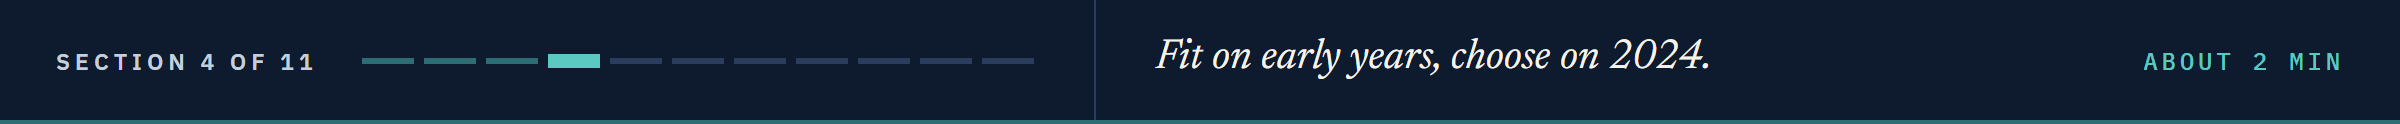

# Splitting by Filing Date

## Three Roles

Course 4's Day 11 split dated rows by date, and so does this notebook: a filer repeats its own wording, and a desk only ever meets later filings.
Here **training** rows fit a model, **validation** rows choose between models, and **test** rows score the chosen one once.
Dates written as text, year first, compare in date order.

In [12]:
# training: filed 2019 to 2023; validation: filed in 2024; the 2025 sections are only counted
train = eightk[eightk["filed"] <= "2023-12-31"]
valid = eightk[(eightk["filed"] > "2023-12-31") & (eightk["filed"] <= "2024-12-31")]
print("training", len(train), train["filed"].min(), "to", train["filed"].max())
print("validation", len(valid), valid["filed"].min(), "to", valid["filed"].max())
print("test, closed until Day 10:", (eightk["filed"] > "2024-12-31").sum())

# sections per item in the two open roles
print(pd.DataFrame({"training": train["item"].value_counts(), "validation": valid["item"].value_counts()}).sort_index().T.to_string())

training 3650 2019-01-02 to 2023-12-29
validation 741 2024-01-03 to 2024-12-31
test, closed until Day 10: 735
item        1.01  1.03  2.02  2.03  2.04  2.06  3.01  5.02
training     500   396   500   500   483   271   500   500
validation   100   100   100   100   100    41   100   100


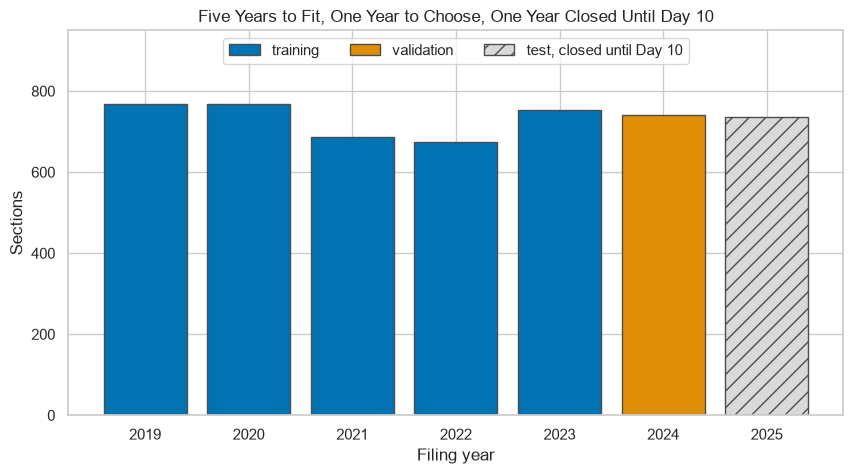

In [13]:
# sections by filing year, coloured by role, 2025 hatched
years = eightk["filed"].str[:4].value_counts().sort_index()
bars = plt.bar(years.index, years, color=["C0"] * 5 + ["C1", "0.85"], edgecolor="0.3")
bars[-1].set_hatch("//")
for bar, role in zip([bars[0], bars[5], bars[6]], ["training", "validation", "test, closed until Day 10"]):
    bar.set_label(role)
plt.legend(loc="upper center", ncol=3)
plt.ylim(0, 950)
plt.xlabel("Filing year")
plt.ylabel("Sections")
plt.title("Five Years to Fit, One Year to Choose, One Year Closed Until Day 10")
plt.show()

### What the Two Sides Share

In [14]:
# validation sections from a filing in training, from a company in training, and bodies equal to a training body
same_company = valid["cik"].isin(train["cik"])
print(valid["accession"].isin(train["accession"]).sum(), "share a filing |", same_company.sum(), f"({same_company.mean():.4f}) share a company |",
      valid["text"].isin(train["text"]).sum(), "bodies equal a training body")

0 share a filing | 338 (0.4561) share a company | 27 bodies equal a training body


No filing sits on both sides, but almost half the validation sections come from a company with a training section.

A wording a company repeats in a later year lands on the validation side, which is how a desk meets it.

**Fit on 2019 to 2023, choose on 2024; Day 10 opens 2025 once.**

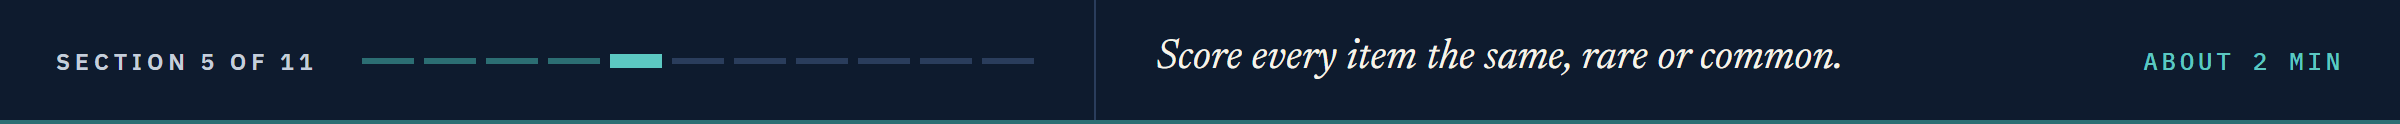

# Scoring Eight Items

## Macro F1

Course 4's Day 7 scored one class: precision, recall and F1 with that class as the positive one.
With eight items, each item gets its own F1, and **macro F1** is their plain mean, so 41 sections of 2.06 weigh as much as 100 of 3.01, and a missed small item costs as much as a missed large one.
**Per-item recall** says what share of each item's sections the model finds.

In [15]:
# macro F1 on four made-up sections, three right and the one 2.06 missed: F1 for each item, then their plain mean
filer = ["1.01", "1.01", "1.01", "2.06"]
model_says = ["1.01", "1.01", "1.01", "1.01"]
print("F1 by item:", f1_score(filer, model_says, labels=["1.01", "2.06"], average=None, zero_division=0).round(4),
      f"| macro F1 {f1_score(filer, model_says, average='macro', zero_division=0):.4f}")

F1 by item: [0.8571 0.    ] | macro F1 0.4286


**Predict 1**

Q. A model that reads nothing assigns every validation section the item most common in training. What is its macro F1 on the 741 validation sections? Write down a number.

## A Model That Reads Nothing

In [16]:
# Course 4's Day 7 majority model: it learns the most common training item and assigns it to every row
baseline = DummyClassifier(strategy="most_frequent").fit(train["text"], train["item"])
base_assigned = baseline.predict(valid["text"])
print("assigns", base_assigned[0], f"| macro F1 {f1_score(valid['item'], base_assigned, average='macro', zero_division=0):.4f}",
      f"| accuracy {(base_assigned == valid['item']).mean():.4f}")
print("F1 by item:", f1_score(valid["item"], base_assigned, labels=LABELS, average=None, zero_division=0).round(4))

assigns 1.01 | macro F1 0.0297 | accuracy 0.1350
F1 by item: [0.2378 0.     0.     0.     0.     0.     0.     0.    ]


Five items tie at 500 training sections, and the model takes the first, 1.01.

Its one F1 above zero is 1.01's; the mean over eight items is close to nothing.

**Any model must clear 0.0297 macro F1 on the 741 validation sections.**

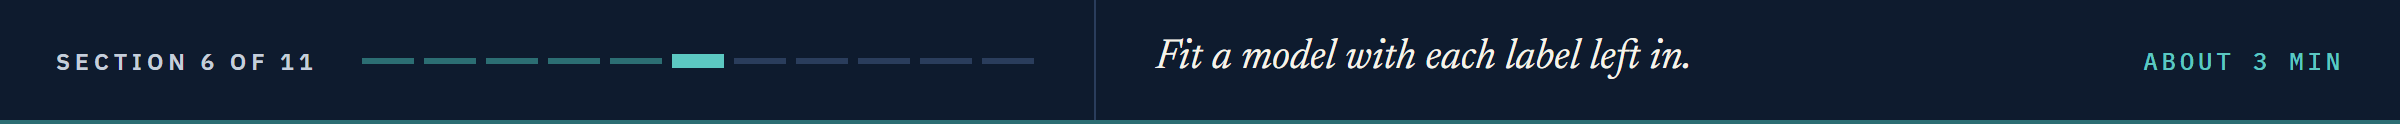

# The Heading Put Back

## A Heading in Front of Each Body

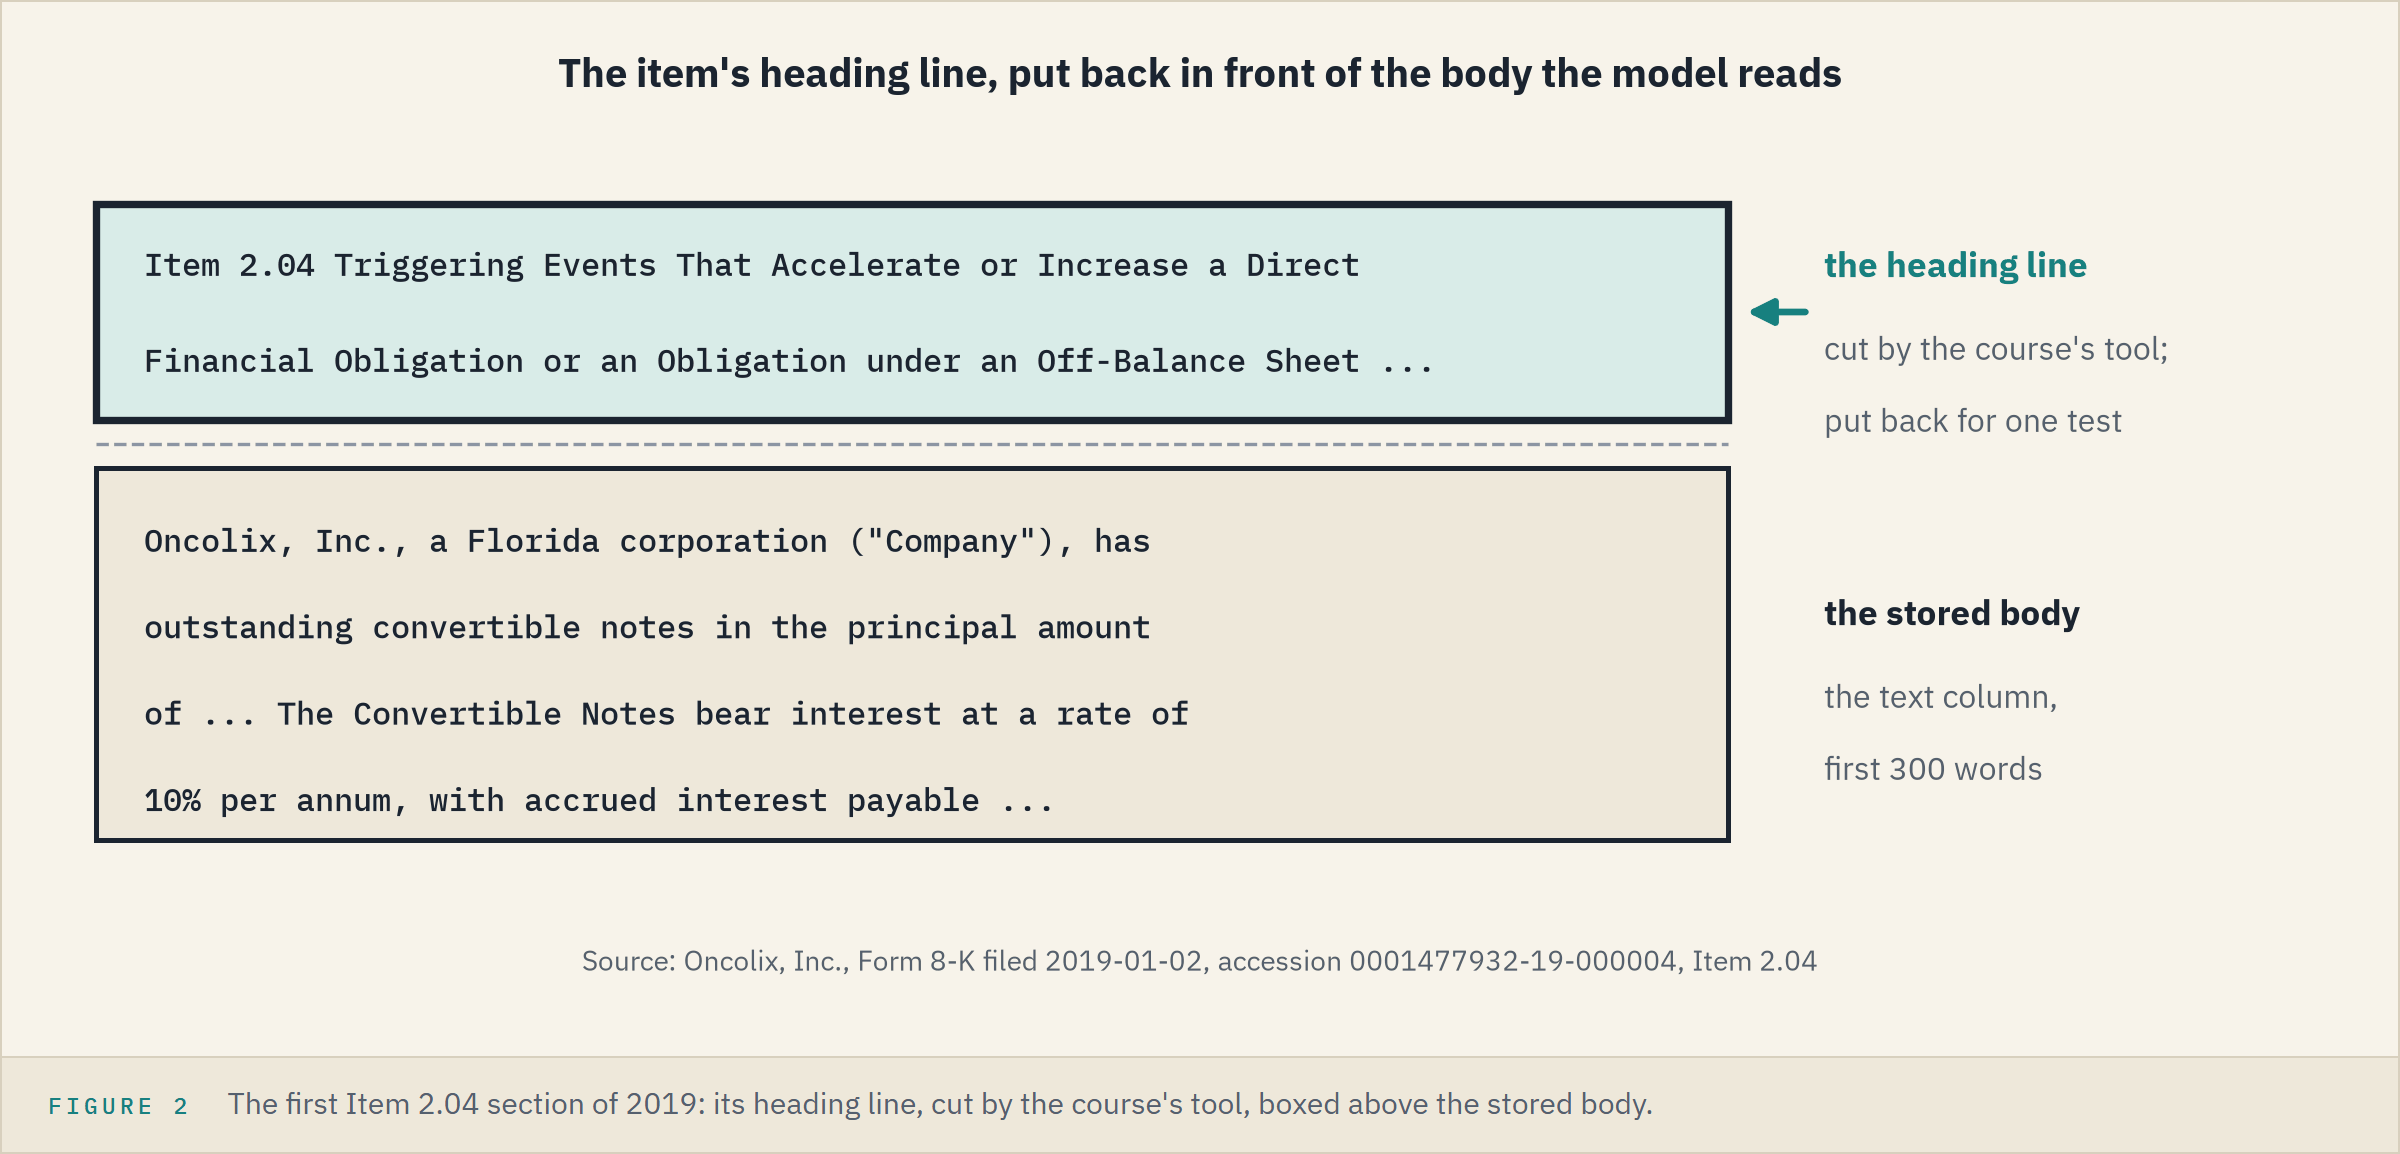

The course's tool cut each section's heading, and the label is written in it.
To see what that does, the next cell puts the heading back on every training and validation section.

In [17]:
# source text: quoted as published
# "Item " + the code + the SEC's title, a line break, then the stored body
train_heading = "Item " + train["item"] + " " + train["item_title"] + "\n" + train["text"]
valid_heading = "Item " + valid["item"] + " " + valid["item_title"] + "\n" + valid["text"]
print(normalize_text(train_heading[first_204.name])[:200])

Item 2.04 Triggering Events That Accelerate or Increase a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement
Oncolix, Inc., a Florida corporation ("Company"), has outs


**Predict 2**

Q. Fit Day 2's TF-IDF and a logistic regression on the training texts with their headings, and score the validation texts with theirs. What macro F1? Write down a number.

## Fitted With Its Label

`make_pipeline` (Course 4) joins Day 2's vectorizer, with the course's settings, and Course 4's Day 6 logistic regression into one model.
The vectorizer learns its vocabulary inside `.fit()`, from the training rows only.

In [18]:
# Day 2's TF-IDF and a logistic regression as one model, fitted on the texts with their headings
leaky = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                      LogisticRegression(max_iter=2000))
leaky.fit(train_heading, train["item"])
leaky_assigned = leaky.predict(valid_heading)
print(f"macro F1 {f1_score(valid['item'], leaky_assigned, average='macro'):.4f} |", (leaky_assigned != valid["item"]).sum(), "of 741 off")
print("recall by item:", recall_score(valid["item"], leaky_assigned, labels=LABELS, average=None).round(4))

macro F1 0.9899 | 6 of 741 off
recall by item: [0.99 0.98 1.   0.97 1.   1.   1.   1.  ]


Only 6 of 741 sections get another item, and every item's recall is 0.97 or more.

### What It Leans On

With eight items the model keeps one row of coefficients per item, in the order of `.classes_`.
A pipeline's steps are read by position: `leaky[0]` is the vectorizer and `leaky[-1]` the model.

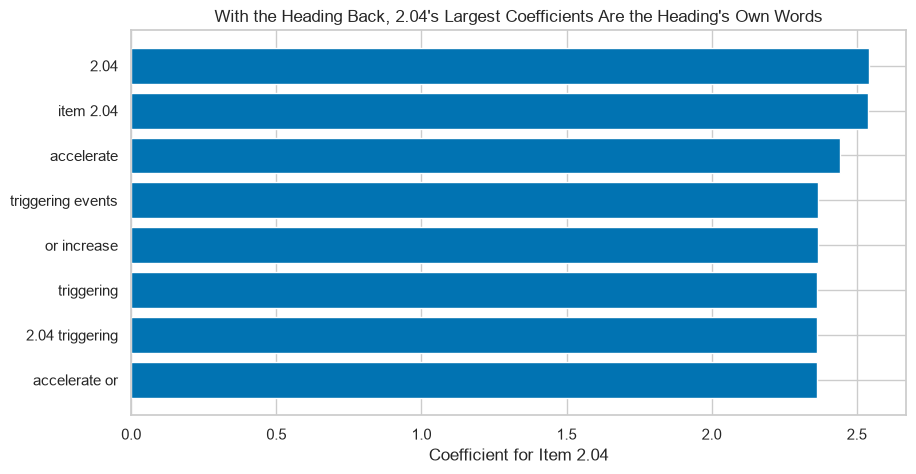

In [19]:
# source text: quoted as published
# the eight largest coefficients for 2.04, ties broken by term (Day 2's np.lexsort)
terms = leaky[0].get_feature_names_out()
row = leaky[-1].coef_[list(leaky[-1].classes_).index("2.04")]
top = np.lexsort((terms, -row))[:8]
plt.barh(terms[top][::-1], row[top][::-1])
plt.xlabel("Coefficient for Item 2.04")
plt.title("With the Heading Back, 2.04's Largest Coefficients Are the Heading's Own Words")
plt.show()

Every bar is a word of the heading: the model has learned to read the label.

**The stored bodies are the fix: from here every model reads `text` as stored.**

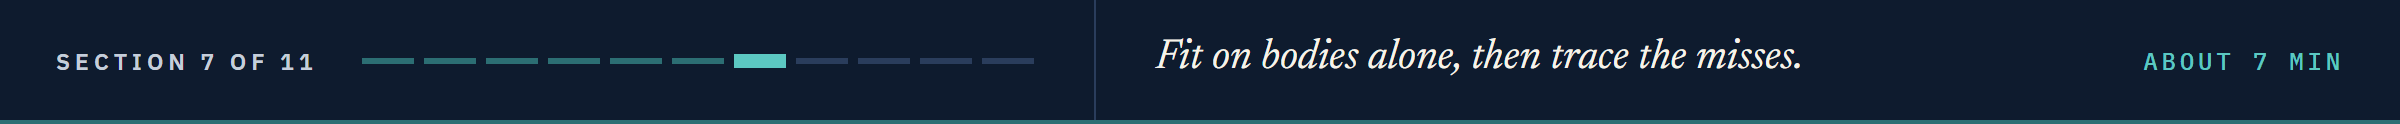

# The Classifier on the Bodies

**Predict 3**

Q. The same pipeline, fitted on the stored bodies alone. Its validation macro F1 lies between 0.0297 and 0.9899: where? Write down a number.

## Fitted on the Bodies

One logistic regression covers all eight items: each section's weighted terms are summed along each item's row of coefficients, and the eight sums become eight probabilities that add to 1.
That last step is the **softmax**, and a logistic regression fitted this way is called **multinomial**.

In [20]:
# the same pipeline on the stored bodies
model = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                      LogisticRegression(max_iter=2000))
model.fit(train["text"], train["item"])
assigned = model.predict(valid["text"])
print(len(model[0].get_feature_names_out()), "terms |", f"macro F1 {f1_score(valid['item'], assigned, average='macro'):.4f} |",
      (assigned != valid["item"]).sum(), "of 741 off")

# precision, recall and F1 for each item, as one table
report = pd.DataFrame({"precision": precision_score(valid["item"], assigned, labels=LABELS, average=None),
                       "recall": recall_score(valid["item"], assigned, labels=LABELS, average=None),
                       "F1": f1_score(valid["item"], assigned, labels=LABELS, average=None)}, index=LABELS)
print(report.round(4).to_string())

40403 terms | macro F1 0.9269 | 52 of 741 off
      precision  recall      F1
1.01     0.8585  0.9100  0.8835
1.03     0.9778  0.8800  0.9263
2.02     0.9709  1.0000  0.9852
2.03     0.8660  0.8400  0.8528
2.04     0.9020  0.9200  0.9109
2.06     0.8810  0.9024  0.8916
3.01     1.0000  1.0000  1.0000
5.02     0.9604  0.9700  0.9652


3.01 is right every time (F1 1.0000), and every 2.02 section is found (recall 1.0000).

2.03 has the lowest F1, 0.8528.

The rare items' recall: 1.03 0.8800, 2.04 0.9200, and 2.06, the smallest, 0.9024.

### The F1 Map

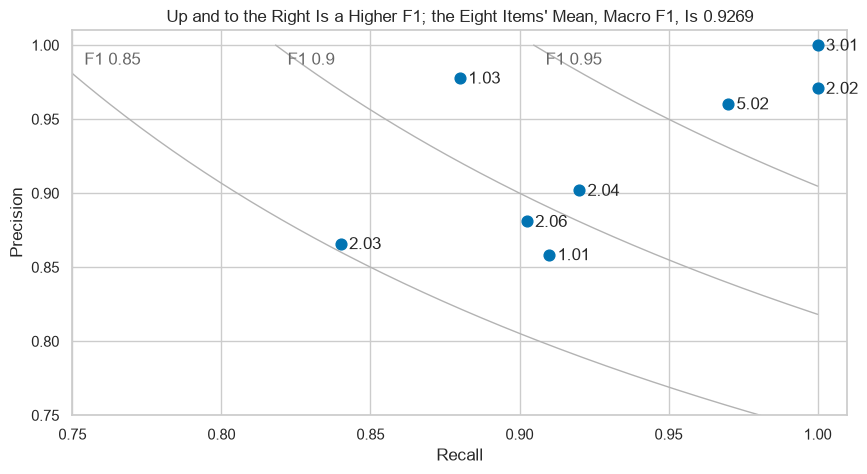

In [21]:
# each item a dot at its recall and precision, over curves where F1 holds one value (precision = F1 x recall / (2 x recall - F1))
for level in [0.85, 0.9, 0.95]:
    recall_grid = np.linspace(level / (2 - level), 1, 200)
    plt.plot(recall_grid, level * recall_grid / (2 * recall_grid - level), color="0.7", lw=1)
    plt.text(max(level / (2 - level), 0.75) + 0.004, 0.995, f"F1 {level}", va="top", color="0.4")
plt.scatter(report["recall"], report["precision"], s=60)
for item, (p, r) in report[["precision", "recall"]].iterrows():
    plt.annotate(item, (r, p), xytext=(6, -4), textcoords="offset points")
plt.gca().set(xlabel="Recall", ylabel="Precision", xlim=(0.75, 1.01), ylim=(0.75, 1.01))
plt.title(f"Up and to the Right Is a Higher F1; the Eight Items' Mean, Macro F1, Is {f1_score(valid['item'], assigned, average='macro'):.4f}")
plt.show()

1.03 sits high and to the left: it seldom takes another item's section (precision 0.9778) and misses more of its own (recall 0.8800).

2.03 sits furthest left (recall 0.8400) and 1.01 lowest (precision 0.8585): other items' sections land in 1.01.

## All Eight at Once

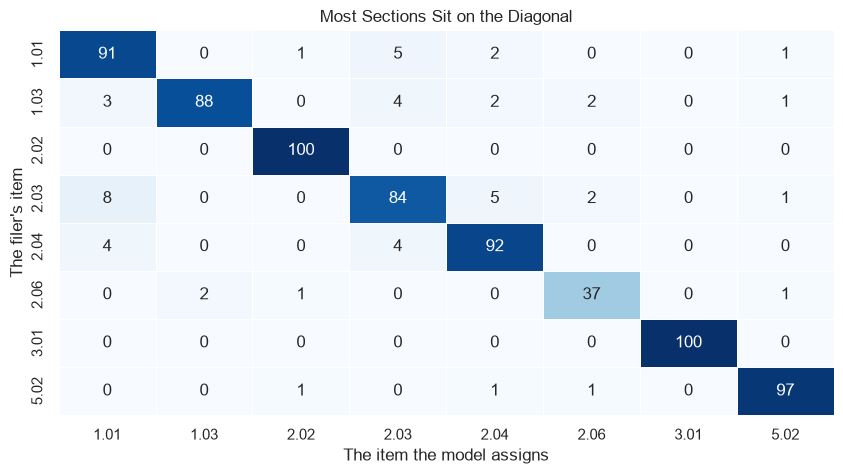

In [22]:
# rows the filer's item, columns the item the model assigns, both in LABELS order
matrix = confusion_matrix(valid["item"], assigned, labels=LABELS)
sns.heatmap(pd.DataFrame(matrix, index=LABELS, columns=LABELS), annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
plt.xlabel("The item the model assigns")
plt.ylabel("The filer's item")
plt.title("Most Sections Sit on the Diagonal")
plt.show()

## Where the 52 Go

A **chord diagram** puts the eight items on a circle and draws one curve for each pair of filer's item and assigned item, its width set by the count.

In [23]:
# the misses only: the matrix with its diagonal set to 0 (np.fill_diagonal), and the eight items around a circle, 1.01 at the top
misses = matrix.copy()
np.fill_diagonal(misses, 0)
angle = np.pi / 2 - 2 * np.pi * np.arange(8) / 8
points = np.column_stack([np.cos(angle), np.sin(angle)])  # one row of x and y per item

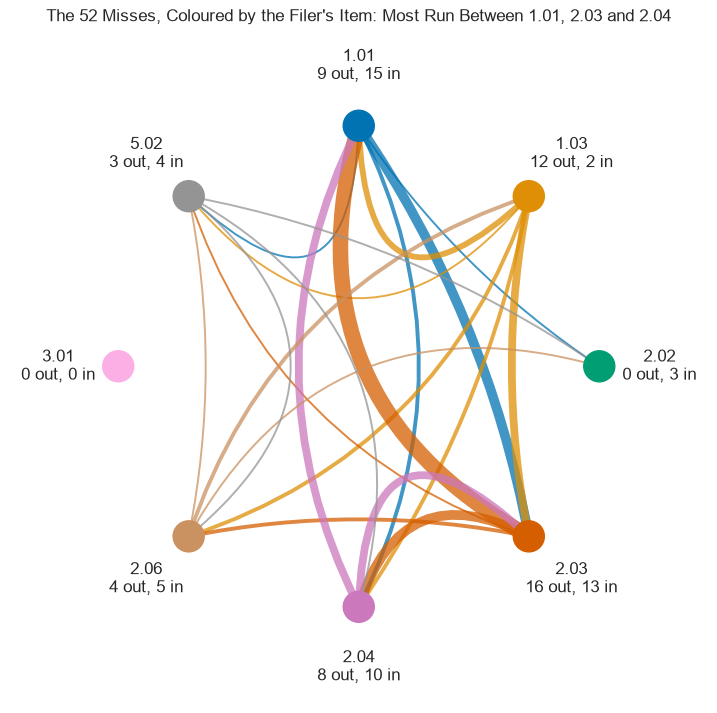

In [24]:
# one curve per pair, from the filer's item (its colour) to the item the model assigns, width by count
# (CurvePath's MOVETO starts a curve, CURVE3 bends it through a control point inside the circle, and PathPatch draws it)
fig, ax = plt.subplots(figsize=(9, 9))
for i in range(8):
    for j in range(8):
        if misses[i, j] > 0:
            bend = 0.15 * (points[i] + points[j]) + 0.25 * np.array([points[i][1] - points[j][1], points[j][0] - points[i][0]])
            curve = CurvePath([points[i], bend, points[j]], [CurvePath.MOVETO, CurvePath.CURVE3, CurvePath.CURVE3])
            ax.add_patch(PathPatch(curve, facecolor="none", edgecolor=colours[i], lw=1.4 * misses[i, j], alpha=0.75, capstyle="round"))
ax.scatter(points[:, 0], points[:, 1], s=500, color=colours, zorder=3)
for k, item in enumerate(LABELS):
    ax.text(*(1.25 * points[k]), f"{item}\n{misses[k].sum()} out, {misses[:, k].sum()} in", ha="center", va="center")
ax.set(xlim=(-1.45, 1.45), ylim=(-1.4, 1.4), aspect="equal", title="The 52 Misses, Coloured by the Filer's Item: Most Run Between 1.01, 2.03 and 2.04")
ax.set_axis_off()
plt.show()

In [25]:
# the pairs with the most misses, largest first (.stack() turns the table into one value per pair of row and column)
pairs = pd.DataFrame(misses, index=LABELS, columns=LABELS).stack()
print(pairs.sort_values(ascending=False, kind="stable").head(6).to_dict())

{('2.03', '1.01'): 8, ('1.01', '2.03'): 5, ('2.03', '2.04'): 5, ('1.03', '2.03'): 4, ('2.04', '1.01'): 4, ('2.04', '2.03'): 4}


The widest curve runs from 2.03 to 1.01 (8 sections), then 1.01 to 2.03 and 2.03 to 2.04 (5 each).

2.02 and 3.01 lose no section, and 2.03 sends out the most, 16.

In [26]:
# source text: quoted as published
# the validation bodies of Item 2.03 the model assigns 1.01: how many name Item 1.01, and the first one's opening
missed = valid[(valid["item"] == "2.03") & (assigned == "1.01")]
print(len(missed), "assigned 1.01 |", missed["text"].str.lower().str.contains("item 1.01", regex=False).sum(), "name Item 1.01")
print(normalize_text(missed["text"].iloc[0])[:300])
section_source(missed.iloc[0])

8 assigned 1.01 | 0 name Item 1.01
Reduction in RMB Facility E to ZAR 0.9 billion
On January 22, 2024, Lesaka Technologies, Inc. ("Lesaka"), through Lesaka Technologies Proprietary Limited ("Lesaka SA"), and FirstRand Bank Limited (acting through its Rand Merchant Bank division) ("RMB"), entered into a Letter of Amendment ("January 2
Source: LESAKA TECHNOLOGIES INC, Form 8-K filed 2024-01-23, accession 0001062993-24-001183, Item 2.03, https://www.sec.gov/Archives/edgar/data/1041514/000106299324001183/form8k.htm


None of the 8 names Item 1.01: the first opens on an amendment of a bank facility, wording much like an agreement's.

## Item 2.04 Against the Rest

One row and one column of the eight-item matrix, read as Course 4's Day 7 matrix with 2.04 the positive class.

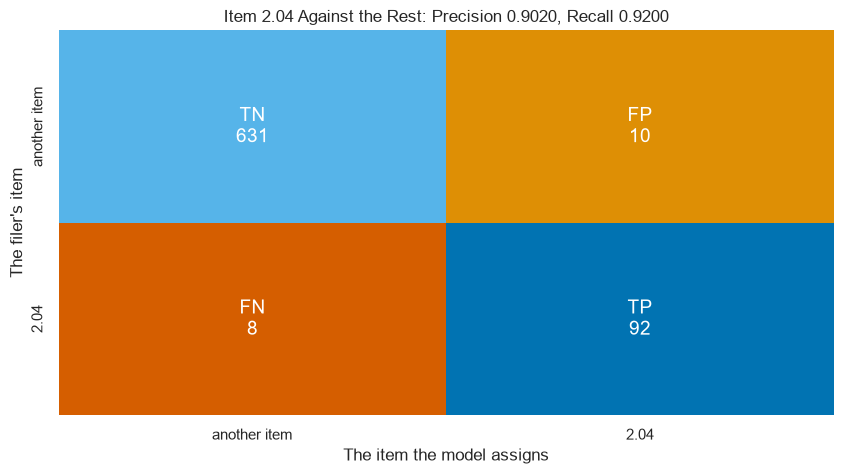

In [27]:
# Item 2.04 against every other item, in Course 4's Day 7 colours
tn, fp, fn, tp = confusion_matrix(valid["item"] == "2.04", assigned == "2.04").ravel()
labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, annot_kws={"size": 14},
            xticklabels=["another item", "2.04"], yticklabels=["another item", "2.04"])
plt.xlabel("The item the model assigns")
plt.ylabel("The filer's item")
plt.title(f"Item 2.04 Against the Rest: Precision {tp / (tp + fp):.4f}, Recall {tp / (tp + fn):.4f}")
plt.show()

The 8 sections of 2.04 assigned elsewhere and the 10 of other items assigned 2.04 are the 2.04 curves of the chord diagram.

## Training Rows Against Validation Rows

In [28]:
# the same scores on the training rows the model was fitted on
train_assigned = model.predict(train["text"])
print(f"training macro F1 {f1_score(train['item'], train_assigned, average='macro'):.4f} |", (train_assigned != train["item"]).sum(), "of", len(train), "off")

training macro F1 0.9758 | 91 of 3650 off


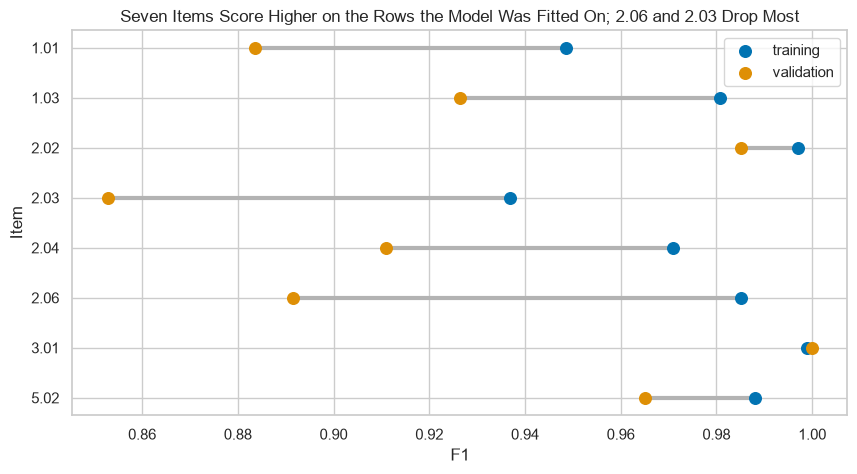

In [29]:
# each item's F1 on training and on validation rows, joined by a line
f1_train = f1_score(train["item"], train_assigned, labels=LABELS, average=None)
plt.hlines(LABELS, report["F1"], f1_train, color="0.7", lw=3)
plt.scatter(f1_train, LABELS, s=70, label="training", zorder=3)
plt.scatter(report["F1"], LABELS, s=70, label="validation", zorder=3)
plt.gca().invert_yaxis()
plt.legend()
plt.xlabel("F1")
plt.ylabel("Item")
plt.title("Seven Items Score Higher on the Rows the Model Was Fitted On; 2.06 and 2.03 Drop Most")
plt.show()

Training macro F1 is 0.9758, 91 of 3,650 off, against 0.9269 on validation.

3.01 alone scores higher on validation, where it is right every time.

**The gap is the model on filings it has not seen; the next two settings move it.**

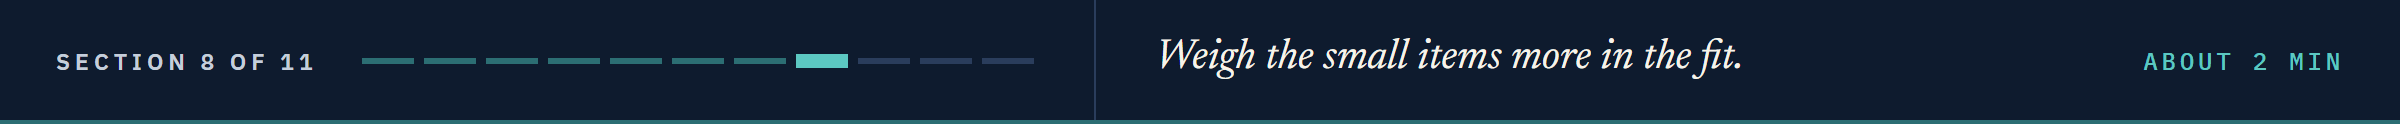

# Class Weights

## Weighting the Small Items

`class_weight="balanced"` (Course 5's Day 13) weighs each training section by 3,650 / (8 x its item's count), so a small item's sections count for more in the fit.
With weights, the model's outputs are scores for each item, no longer probabilities in this file.

In [30]:
# the weight each item's sections get
weights = len(train) / (8 * train["item"].value_counts().sort_index())
print(weights.round(4).to_dict())

{'1.01': 0.9125, '1.03': 1.1521, '2.02': 0.9125, '2.03': 0.9125, '2.04': 0.9446, '2.06': 1.6836, '3.01': 0.9125, '5.02': 0.9125}


**Predict 4**

Q. Refit the same pipeline with these weights. Of the 741 validation sections, how many does it assign a different item from the model without weights? Write down a number.

## What the Weights Move

In [31]:
# the same pipeline with class_weight="balanced", and the sections whose item changes
weighted = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                         LogisticRegression(max_iter=2000, class_weight="balanced"))
weighted_assigned = weighted.fit(train["text"], train["item"]).predict(valid["text"])
moved = weighted_assigned != assigned
print(moved.sum(), "changed |", f"macro F1 {f1_score(valid['item'], weighted_assigned, average='macro'):.4f} against {f1_score(valid['item'], assigned, average='macro'):.4f}")
print(pd.DataFrame({"filer": valid["item"][moved], "without weights": assigned[moved], "with weights": weighted_assigned[moved]}).to_string(index=False))

3 changed | macro F1 0.9271 against 0.9269
filer without weights with weights
 2.03            2.03         2.04
 1.03            1.01         2.06
 2.06            1.03         2.06


In [32]:
# recall of four items without and with the weights
four = ["1.03", "2.03", "2.04", "2.06"]
print("without:", recall_score(valid["item"], assigned, labels=four, average=None).round(4))
print("with:   ", recall_score(valid["item"], weighted_assigned, labels=four, average=None).round(4))

without: [0.88   0.84   0.92   0.9024]
with:    [0.88   0.83   0.92   0.9268]


2.06's recall rises from 0.9024 to 0.9268, one more of its 41 sections; 2.03's falls from 0.84 to 0.83.

Macro F1 moves from 0.9269 to 0.9271.

**At the default penalty the weights move 3 sections; the penalty decides how much room they have.**

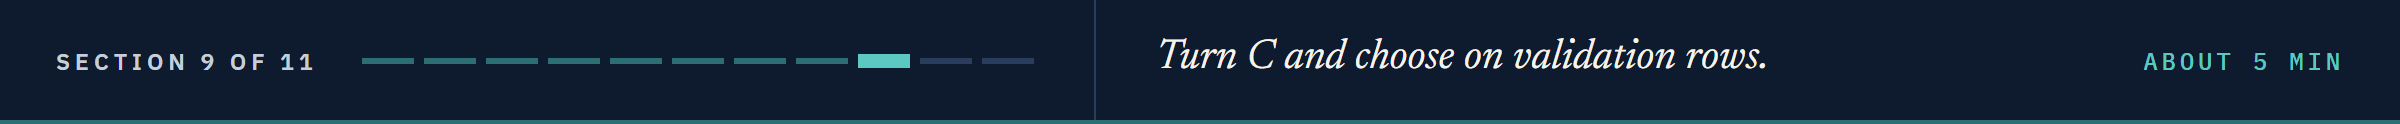

# The Penalty C

## What C Holds Back

Course 4's Day 6 `C`: the smaller it is, the harder the coefficients are held back toward zero.
Ten fits follow: five values of `C`, each without and with weights, kept in a dictionary under (`C`, weights).

In [33]:
# ten fits, about a minute in all
fits = {}
for C in [0.01, 0.1, 1, 10, 100]:
    for weight in [None, "balanced"]:
        fits[(C, weight)] = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                                          LogisticRegression(C=C, max_iter=2000, class_weight=weight)).fit(train["text"], train["item"])
print(len(fits), "fits")

10 fits


**Predict 5**

Q. Sketch training and validation macro F1 against `C` from 0.01 to 100, no weights. Where are the two curves close, where do they part, and where does validation peak?

## Training and Validation Against C

In [34]:
# macro F1 on training and on validation rows for every fit
scores = pd.DataFrame([{"C": C, "weights": str(weight), "training": f1_score(train["item"], fit.predict(train["text"]), average="macro"),
                        "validation": f1_score(valid["item"], fit.predict(valid["text"]), average="macro")} for (C, weight), fit in fits.items()])
print(scores.round(4).to_string(index=False))

     C  weights  training  validation
  0.01     None    0.7152      0.7198
  0.01 balanced    0.8639      0.8666
  0.10     None    0.8838      0.8811
  0.10 balanced    0.9022      0.8908
  1.00     None    0.9758      0.9269
  1.00 balanced    0.9762      0.9271
 10.00     None    0.9997      0.9429
 10.00 balanced    0.9997      0.9397
100.00     None    0.9997      0.9391
100.00 balanced    0.9997      0.9416


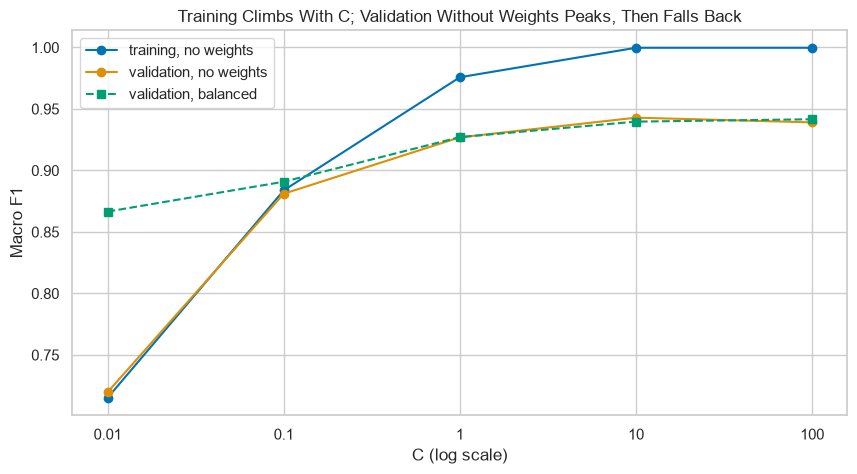

In [35]:
# macro F1 against C on a log axis: training and validation without weights, validation with them
plain, balanced = scores[scores["weights"] == "None"], scores[scores["weights"] == "balanced"]
plt.plot(plain["C"], plain["training"], marker="o", label="training, no weights")
plt.plot(plain["C"], plain["validation"], marker="o", label="validation, no weights")
plt.plot(balanced["C"], balanced["validation"], marker="s", linestyle="--", label="validation, balanced")
plt.xscale("log")
plt.xticks([0.01, 0.1, 1, 10, 100], ["0.01", "0.1", "1", "10", "100"])
plt.legend()
plt.xlabel("C (log scale)")
plt.ylabel("Macro F1")
plt.title("Training Climbs With C; Validation Without Weights Peaks, Then Falls Back")
plt.show()

### Interpretation of the Curves

At `C` = 0.01 training and validation sit together near 0.72, and the weights lift validation to 0.8666.

From `C` = 1 the curves part: training reaches 0.9997 at 10, while validation peaks at 0.9429 there and falls to 0.9391 at 100.

With weights, validation keeps rising to 0.9416 at 100.

## Your Turn: Move C

Pick a `C` and the weights, and see the eight-item matrix of that stored fit.

In [36]:
# the 8 x 8 matrix of any stored fit
def draw_matrix(C=0.01, weights="None"):
    fit = fits[(C, None if weights == "None" else "balanced")]
    table = confusion_matrix(valid["item"], fit.predict(valid["text"]), labels=LABELS)
    sns.heatmap(pd.DataFrame(table, index=LABELS, columns=LABELS), annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
    plt.xlabel("The item the model assigns")
    plt.ylabel("The filer's item")
    plt.title(f"C = {C}, Weights {weights}: {np.diagonal(table).sum()} of 741 Sections on the Diagonal")
    plt.show()


interact(draw_matrix, C=[0.01, 0.1, 1, 10, 100], weights=["None", "balanced"]);

interactive(children=(Dropdown(description='C', options=(0.01, 0.1, 1, 10, 100), value=0.01), Dropdown(descrip…

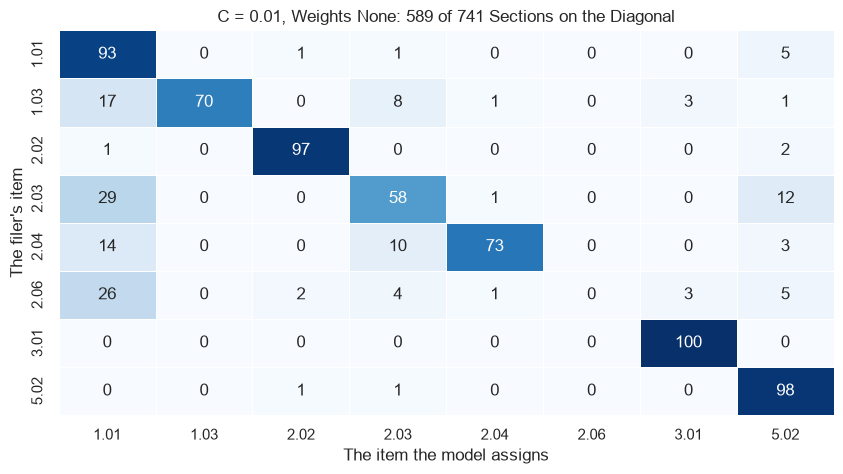

In [37]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_matrix(0.01, "None")

At `C` = 0.01 no section is assigned 2.06: 26 of its 41 go to 1.01.

Move to `C` = 10 and the 2.06 column fills again.

## Choosing on Validation

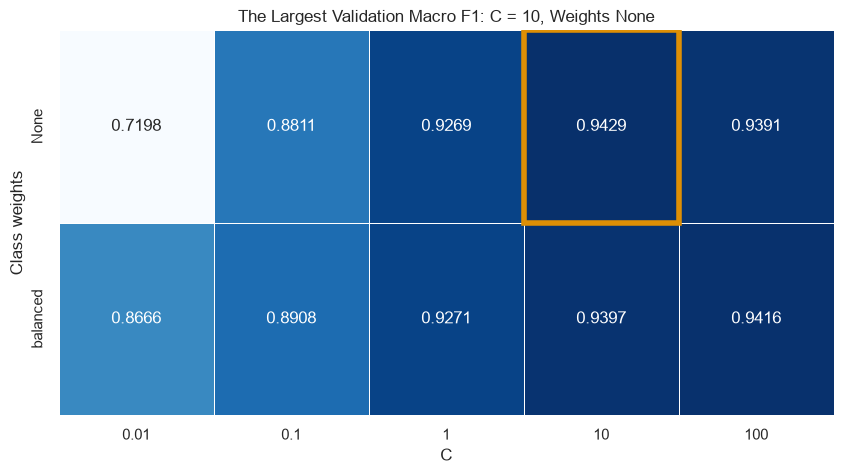

In [38]:
# validation macro F1 as a grid, C across and the weights down, the largest outlined
grid = scores.pivot(index="weights", columns="C", values="validation")
ax = sns.heatmap(grid, annot=True, fmt=".4f", cmap="Blues", cbar=False, linewidths=0.5, xticklabels=["0.01", "0.1", "1", "10", "100"])
best = scores.loc[scores["validation"].idxmax()]
ax.add_patch(plt.Rectangle((list(grid.columns).index(best["C"]), list(grid.index).index(best["weights"])), 1, 1, fill=False, edgecolor="C1", lw=4))
ax.set(xlabel="C", ylabel="Class weights", title=f"The Largest Validation Macro F1: C = {best['C']:g}, Weights {best['weights']}")
plt.show()

In [39]:
# the course's 8-K classifier: the largest validation macro F1 of the ten
chosen = fits[(10, None)]
chosen_assigned = chosen.predict(valid["text"])
print(f"macro F1 {f1_score(valid['item'], chosen_assigned, average='macro'):.4f} | accuracy {(chosen_assigned == valid['item']).mean():.4f} |",
      (chosen_assigned != valid["item"]).sum(), "of 741 off | training:", (chosen.predict(train["text"]) != train["item"]).sum(), "of", len(train), "off")
print("recall 1.03, 2.04, 2.06:", recall_score(valid["item"], chosen_assigned, labels=["1.03", "2.04", "2.06"], average=None).round(4))
print("next, balanced C = 100:", (fits[(100, "balanced")].predict(valid["text"]) != valid["item"]).sum(), "of 741 off")

macro F1 0.9429 | accuracy 0.9460 | 40 of 741 off | training: 1 of 3650 off
recall 1.03, 2.04, 2.06: [0.93   0.94   0.9268]
next, balanced C = 100: 41 of 741 off


Balanced `C=100` sits one section behind, so the choice rests on a margin of one section.

The model fits its own training rows almost perfectly; the validation score is the honest one.

Day 10 opens the 2025 sections once, for this model.

**The course's 8-K classifier from here: `C=10`, no class weights, chosen on the 741 validation sections; 2025 stays closed.**

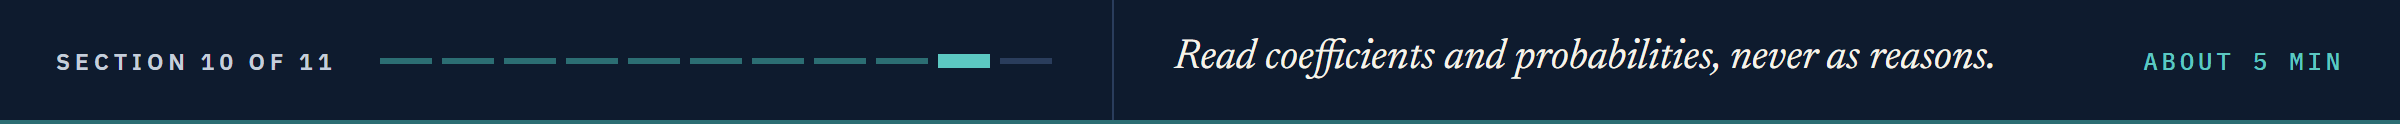

# What the Model Leans On

## Coefficients by Item

In [40]:
# source text: quoted as published
# each item's three largest coefficients in the chosen model, ties broken by term
terms = chosen[0].get_feature_names_out()
coef = chosen[-1].coef_
top3 = {item: np.lexsort((terms, -coef[k]))[:3] for k, item in enumerate(chosen.classes_)}
for item, columns in top3.items():
    print(item, terms[columns].tolist())

1.01 ['agreement', 'entered into', 'amendment']
1.03 ['court', 'bankruptcy', '1.03']
2.02 ['release', 'press release', 'press']
2.03 ['item 2.03', '2.03', 'item 1.01']
2.04 ['2.04', 'default', 'item 2.04']
2.06 ['impairment', 'item 2.05', '2.05']
3.01 ['nasdaq', 'listing', 'nyse']
5.02 ['mr', 'effective', 'his']


A **Hinton diagram** (Course 6's Day 3) draws each number as a square: its area the size, its colour the sign.

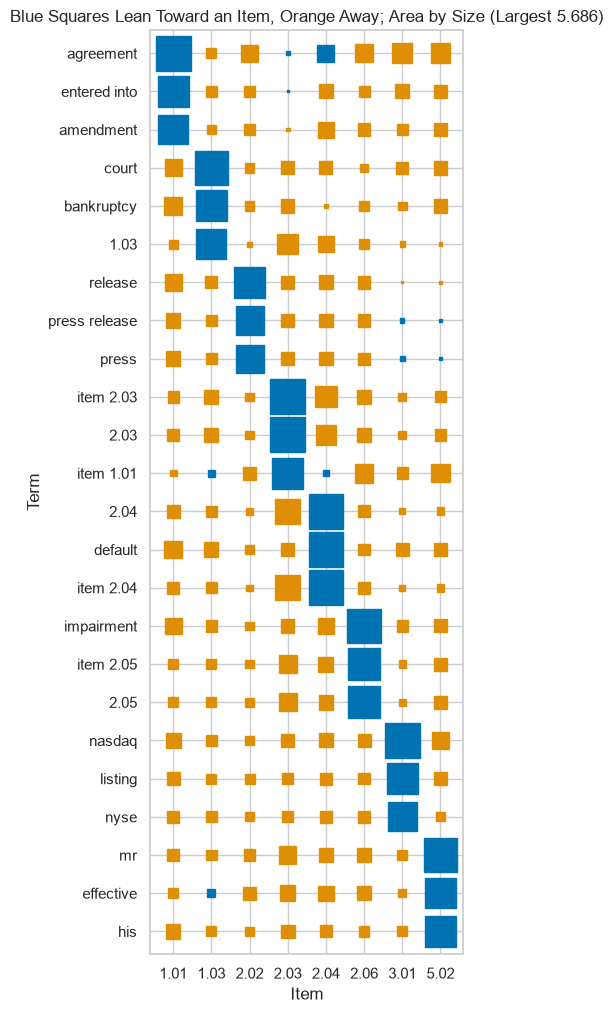

In [41]:
# the 24 terms down, the 8 items across: blue squares above zero, orange below (pd.unique keeps each term once, in order)
picked = pd.unique(np.concatenate(list(top3.values())))
block = coef[:, picked].T
fig, ax = plt.subplots(figsize=(8, 12))
for r in range(len(picked)):
    for c in range(8):
        side = 0.92 * np.sqrt(abs(block[r, c]) / np.abs(block).max())
        ax.add_patch(plt.Rectangle((c - side / 2, r - side / 2), side, side, color="C0" if block[r, c] > 0 else "C1"))
ax.set(xlim=(-0.6, 7.6), ylim=(len(picked) - 0.4, -0.6), aspect="equal", xticks=range(8), xticklabels=LABELS,
       yticks=range(len(picked)), yticklabels=terms[picked], xlabel="Item", ylabel="Term")
ax.set_title(f"Blue Squares Lean Toward an Item, Orange Away; Area by Size (Largest {np.abs(block).max():.3f})")
plt.show()

1.03 leans on court and bankruptcy, 2.02 on press release, 3.01 on nasdaq, listing and nyse.

2.03's largest coefficients are item numbers; 384 of 700 Item 2.03 bodies name Item 1.01.

2.06 leans on impairment, then on another item's number, 2.05.

5.02's are mr, effective and his: words its filers write when they name an officer and the date a change takes effect.

A coefficient is what this fitted model leans on in this file, never a reason and never a description of a company or a person.

> STORY: Where the item numbers come from.
> On 2004-03-16 the SEC issued Release 33-8400, "Additional Form 8-K Disclosure Requirements and Acceleration of Filing Date", effective 2004-08-23.
> It added eight new items to the form, reorganized the items "into topical categories", and shortened the deadline for most items to four business days after the event.
> Five of this file's eight items are among the new ones: 1.01, 2.03, 2.04, 2.06 and 3.01.
> Source: the SEC's page for the release, https://www.sec.gov/rule-release/33-8400, and the rule as printed in the Federal Register of 2004-03-25, https://www.govinfo.gov/content/pkg/FR-2004-03-25/html/04-6332.htm (both read 2026-11-18)

## Bodies That Name Their Own Item

{'1.01': '0.0300', '1.03': '0.0884', '2.02': '0.5780', '2.03': '0.4420', '2.04': '0.1242', '2.06': '0.2103', '3.01': '0.0720', '5.02': '0.0080'}
84 of 271 training 2.06 bodies name Item 2.05


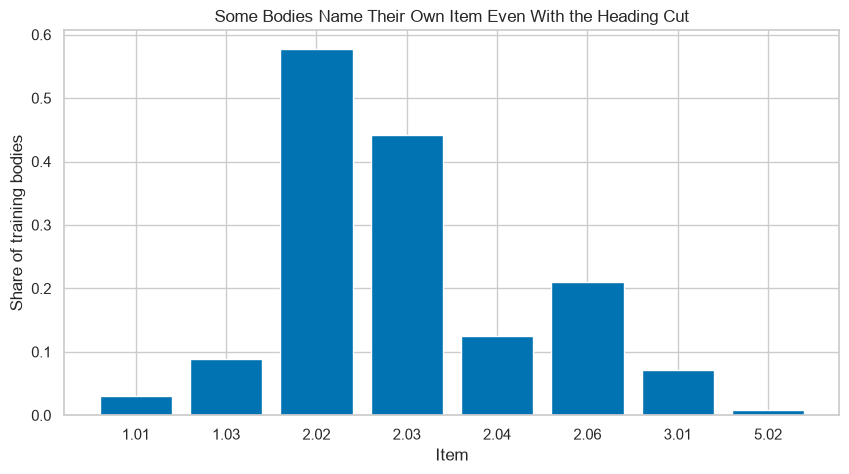

In [42]:
# the share of each item's training bodies that name their own item, as "Item 2.03" or "item 2.03"
own = pd.Series({item: train.loc[train["item"] == item, "text"].str.lower().str.contains(f"item {item}", regex=False).mean() for item in LABELS})
print({item: f"{share:.4f}" for item, share in own.items()})

# the training 2.06 bodies that name Item 2.05, another item's number
is_206 = train["item"] == "2.06"
print(train.loc[is_206, "text"].str.lower().str.contains("item 2.05", regex=False).sum(), "of", is_206.sum(), "training 2.06 bodies name Item 2.05")
plt.bar(own.index, own)
plt.xlabel("Item")
plt.ylabel("Share of training bodies")
plt.title("Some Bodies Name Their Own Item Even With the Heading Cut")
plt.show()

0.5780 of the 2.02 bodies and 0.4420 of the 2.03 bodies name their own item: a cross-reference the filer writes, never the cut heading.

84 of the 271 training 2.06 bodies name Item 2.05, the number 2.06 leans on after impairment.

Exercise 2 takes every item number out and measures what the numbers are worth.

## Eight Probabilities a Section

In [43]:
# source text: quoted as published
# the first Item 2.04 section of 2024: the chosen model's eight probabilities, which add to 1
first_2024 = valid[valid["item"] == "2.04"].iloc[0]
proba = chosen.predict_proba([first_2024["text"]])[0]
print({item: f"{p:.4f}" for item, p in zip(chosen.classes_, proba)}, f"| sum {proba.sum():.4f}")
print(normalize_text(first_2024["text"])[:200])
section_source(first_2024)

{'1.01': '0.0091', '1.03': '0.0031', '2.02': '0.0008', '2.03': '0.0189', '2.04': '0.9629', '2.06': '0.0020', '3.01': '0.0023', '5.02': '0.0008'} | sum 1.0000
The proceedings in Japan described in Item 1.03 above constitute an event of default pursuant to the secured convertible notes in the aggregate principal amount of $4,200,000 (collectively, the "Notes
Source: AERWINS Technologies Inc., Form 8-K filed 2024-01-03, accession 0001493152-24-000337, Item 2.04, https://www.sec.gov/Archives/edgar/data/1855631/000149315224000337/form8-k.htm


The model's probability for Item 2.04 in this file is 0.9629; the next largest, 2.03's, is 0.0189.

A **structure plot** draws every section as one thin column of its eight probabilities, stacked to 1.

In [44]:
# every validation section's eight probabilities, how sure the model is, and an order: by the filer's item, then by the
# probability of that item, largest first, with a gap of 12 columns between items (np.searchsorted finds each item's place)
probs = chosen.predict_proba(valid["text"])
print(f"largest probability above 0.9: {(probs.max(axis=1) > 0.9).mean():.4f} of the sections | median {np.median(probs.max(axis=1)):.4f}")
own_prob = probs[np.arange(len(valid)), [LABELS.index(item) for item in valid["item"]]]
order = np.lexsort((-own_prob, valid["item"].to_numpy()))
place = np.arange(len(valid)) + 12 * np.searchsorted(LABELS, valid["item"].to_numpy()[order])

largest probability above 0.9: 0.7584 of the sections | median 0.9759


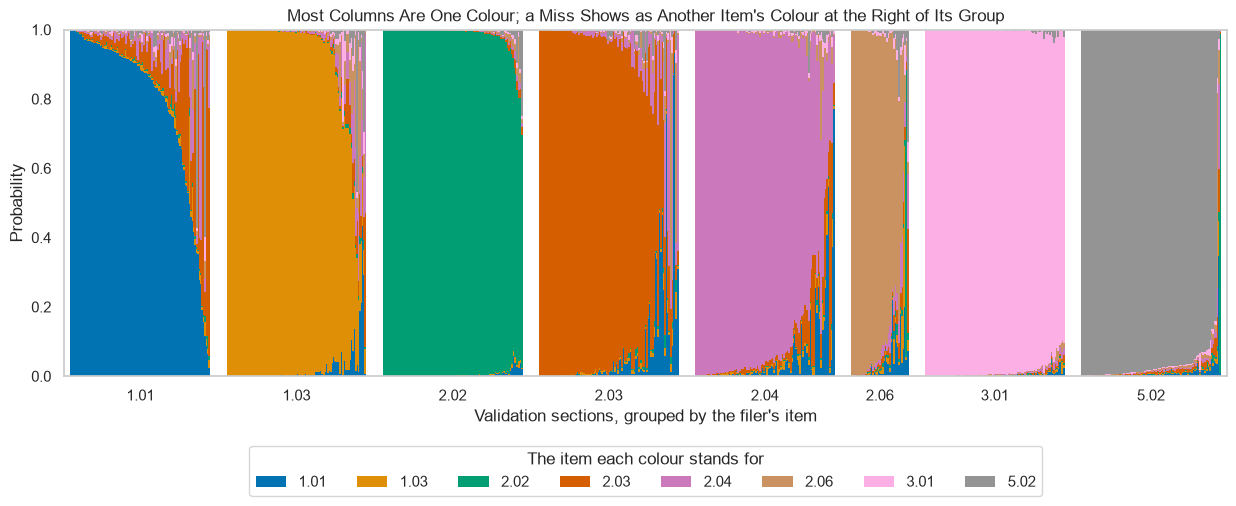

In [45]:
# the structure plot: each section a column, its eight probabilities stacked in the items' colours (antialiased=False keeps thin columns sharp)
fig, ax = plt.subplots(figsize=(15, 4.5))
bottom = np.zeros(len(valid))
for k in range(8):
    ax.bar(place, probs[order, k], bottom=bottom, width=1.4, color=colours[k], linewidth=0, antialiased=False, label=LABELS[k])
    bottom = bottom + probs[order, k]
ax.set(xticks=[place[valid["item"].to_numpy()[order] == item].mean() for item in LABELS], xticklabels=LABELS, xlim=(-5, place.max() + 5),
       ylim=(0, 1), xlabel="Validation sections, grouped by the filer's item", ylabel="Probability",
       title="Most Columns Are One Colour; a Miss Shows as Another Item's Colour at the Right of Its Group")
ax.grid(False)
ax.legend(ncol=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), title="The item each colour stands for")
plt.show()

For 0.7584 of the sections the model's largest probability is above 0.9, and its median is 0.9759.

A column with two broad colours is a section whose wording sits between two items.

**The item the model assigns is the largest of eight probabilities: it says which items' wording a section resembles, nothing about the company.**

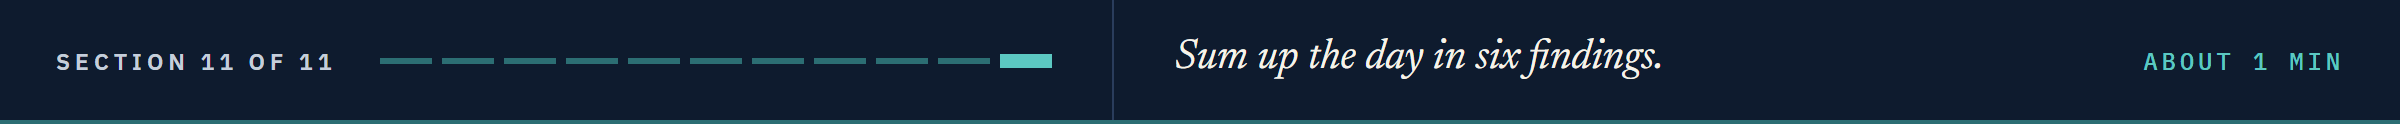

# Insights and Conclusion

The file's counts are the course's design: five items hold 700 sections, 2.06 only 363.

With the heading put back, macro F1 is 0.9899; on the bodies alone 0.9269; the majority baseline 0.0297.

The 52 misses gather among 1.01, 2.03 and 2.04, whose titles name agreements and obligations.

Class weights move 3 sections at `C` = 1, and lift `C` = 0.01 from 0.7198 to 0.8666.

`C` = 10 without weights is chosen on validation, at 0.9429.

2.03's largest coefficients are item numbers; 384 of 700 Item 2.03 bodies name Item 1.01.

**Label out of the text, rows split by date, every item counted the same: then the score means something.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Split dated documents into training, validation and closed test rows by date.
* Score a classifier on eight items with macro F1 and per-item recall, against a majority baseline.
* Find a label left in the text, and take it out.
* Fit TF-IDF and a logistic regression as one pipeline, and read its eight-item confusion matrix.
* Turn `class_weight` and `C`, and choose a model on validation rows.
* Read a model's coefficients and probabilities for what they are.

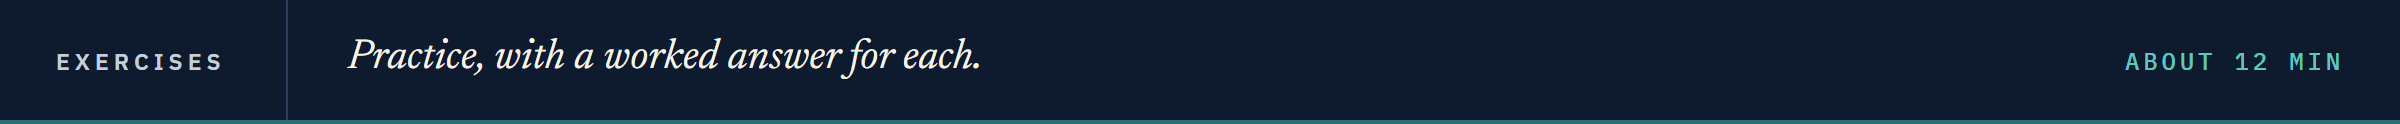

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The First 100 Words**

Q. Fit the chosen settings (`C=10`, no weights) on the first 100 words of each training body, and score the first 100 words of each validation body. `.str.split().str[:100].str.join(" ")` keeps a text's first 100 words. Store the validation macro F1 in `ex1_f1`.

In [47]:
# your code here
ex1_f1 = ...

In [48]:
check("Exercise 1 macro F1 on the first 100 words", ex1_f1, 0.9141084196592758)

Exercise 1 macro F1 on the first 100 words: not attempted yet


### Exercise 2

**Every Item Number Taken Out**

Q. Replace every item number in the bodies, "Item 1.01" or "Items 2.03", by the word alone with `.str.replace(r"(?i)\b(items?)\s+\d\.\d\d\b", r"\1", regex=True)`. `(?i)` makes the pattern ignore case, and `\1` puts back what the first bracket matched. Fit the chosen settings on the training bodies so changed, score the validation bodies so changed, and store the macro F1 in `ex2_f1` and Item 2.04's recall in `ex2_recall_204`.

In [49]:
# your code here
ex2_f1 = ...
ex2_recall_204 = ...

In [50]:
check("Exercise 2 macro F1 without item numbers", ex2_f1, 0.9298619359067399)
check("Exercise 2 recall of Item 2.04", ex2_recall_204, 0.89)

Exercise 2 macro F1 without item numbers: not attempted yet
Exercise 2 recall of Item 2.04: not attempted yet


### Exercise 3

**A Function for the Rare Items**

Q. Write `rare_item_recall(filer_items, assigned_items, items)`, which returns a dictionary of each listed item's recall rounded to 4 decimals, in the order given. Store `rare_item_recall(valid["item"], chosen_assigned, ["1.03", "2.04", "2.06"])` in `ex3_recall`.

In [51]:
# your code here
ex3_recall = ...

In [52]:
check("Exercise 3 recall of the rare items", ex3_recall, {'1.03': 0.93, '2.04': 0.94, '2.06': 0.9268})

Exercise 3 recall of the rare items: not attempted yet


### Exercise 4: AI check

**A Fair Mix of Sections**

You asked an AI assistant for training and validation sections for a fair test of the chosen settings.
This came back.
Before you run the test below, write down whether its macro F1 will sit above or below the chosen model's 0.9429, then find the one bug.

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
from sklearn.model_selection import train_test_split


def split_sections(frame):
    """Training and validation sections for a fair test of a classifier, from the 2019 to 2024 sections."""
    known = frame[frame["filed"] <= "2024-12-31"]
    return train_test_split(known, test_size=0.2, random_state=SEED)

In [54]:
# the docstring's promise, tested: the chosen settings fitted and scored, then the dates and filings on each side
ai_train, ai_valid = split_sections(eightk)
ai_model = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                         LogisticRegression(C=10, max_iter=2000)).fit(ai_train["text"], ai_train["item"])
print(len(ai_train), len(ai_valid), f"| macro F1 {f1_score(ai_valid['item'], ai_model.predict(ai_valid['text']), average='macro'):.4f}")
print("last training date", ai_train["filed"].max(), "| first validation date", ai_valid["filed"].min(), "|",
      ai_valid["accession"].isin(ai_train["accession"]).sum(), "validation sections share a filing with training")

3512 879 | macro F1 0.9496
last training date 2024-12-30 | first validation date 2019-01-03 | 40 validation sections share a filing with training


Q. Fix the one wrong idea: split the 2019 to 2024 sections by date as this notebook does, fit the same settings, and store the validation macro F1 in `ex4_f1`.

In [55]:
# your code here
ex4_f1 = ...

In [56]:
check("Exercise 4 macro F1 split by date", ex4_f1, 0.9429164610382119)

Exercise 4 macro F1 split by date: not attempted yet


## Congratulations!

You turned 5,126 real 8-K sections into a classifier that assigns each one of eight items.
You split the filings by date, kept 2025 closed, and scored every item the same, rare or common.
You caught a label hiding in the text, read where the misses go, and chose a model on rows it had never seen.
Day 4 gives each word a vector learned from a large body of text, and sets those vectors against today's model.

[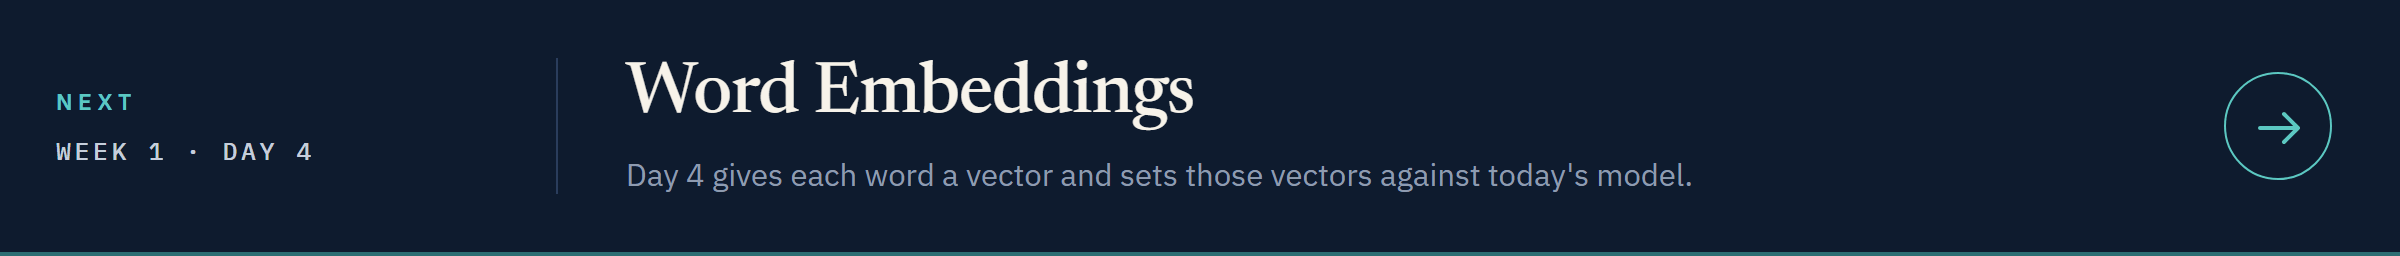](../day4/04_word_embeddings.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day4/04_word_embeddings.ipynb)